In [1]:
import pandas as pd
import numpy as np
from cmdstanpy import CmdStanModel
import geopandas as gpd
from libpysal import weights
from sklearn.preprocessing import LabelEncoder
import networkx as nx
import re
from scipy.sparse import diags

/home/roberto-cerina/stan_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df = pd.read_csv('../generated_data/feature_extraction/all_results.csv')

In [4]:
print(df.columns)

Index(['id', 'time_window_start', 'tweets_struct', 'name', 'username',
       'description', 'location', 'public_metrics.followers_count',
       'profile_image_url', 'clean...pool',
       ...
       'Demo_interest_in_politics_Symbol',
       'Demo_interest_in_politics_Speculation', 'Demo_marital_status_Category',
       'Demo_marital_status_Explanation', 'Demo_marital_status_Symbol',
       'Demo_marital_status_Speculation', 'Demo_partisan_loyalties_Category',
       'Demo_partisan_loyalties_Explanation', 'Demo_partisan_loyalties_Symbol',
       'Demo_partisan_loyalties_Speculation'],
      dtype='object', length=227)


In [30]:
df = df[['id', 'time_window_start', 'username', 'Demo_sex_Symbol', 'Demo_age_Symbol', 'Demo_ethnicity_Symbol', 'Demo_highest_educational_qualification_Symbol','Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol', 'Demo_interest_in_politics_Symbol', 'Demo_marital_status_Symbol', 'Demo_partisan_loyalties_Symbol','Demo_which_state_of_the_usa_do_they_live_in__Category','Demo_household_income_bracket_Symbol','Belief_opinion_on_declining_share_of_white_people_in_america_Symbol']]

In [32]:
df_filtered

,id,time_window_start,username,Demo_sex_Symbol,Demo_age_Symbol,Demo_ethnicity_Symbol,Demo_highest_educational_qualification_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_interest_in_politics_Symbol,Demo_marital_status_Symbol,Demo_partisan_loyalties_Symbol,Demo_which_state_of_the_usa_do_they_live_in__Category,Demo_household_income_bracket_Symbol,Belief_opinion_on_declining_share_of_white_people_in_america_Symbol
10,1081532502966239232,2024-03-24 00:00:00+00:00,xxaleb,s1),a2),e1),q1),vpa3),i3),m2),pid3),not from a state in the usa,h2),rab2)
11,1081532502966239232,2024-04-07 00:00:00+00:00,xxaleb,s1,a2,e1,q1,vpa1,i3,m2,pid4,not from a state in the usa,h2,rab2)
12,1081532502966239232,2024-04-21 00:00:00+00:00,xxaleb,s1),a2),e1),q2),vpa1),i3),m2),pid4),usa,h2),rab2)
13,1081532502966239232,2024-05-05 00:00:00+00:00,xxaleb,s1),a2),e1),q2),vpa1),i3),m2),pid3),not from a state in the usa,h1),rab1)
14,1081532502966239232,2024-05-19 00:00:00+00:00,xxaleb,s1),a2),e1),q2),vpa3),i1),m2),pid4),not from a state in the usa,h3),rab3)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23985,142827500,2024-08-25 00:00:00+00:00,ndrwwwww,s1),a3),e1),q2),vpa3),i4),m2),pid3),illinois,h3),rab3)
23986,142827500,2024-09-08 00:00:00+00:00,ndrwwwww,s1),a3),e1),q2),vpa3),i3),m2),pid3),illinois,h4),rab3)
23987,142827500,2024-09-22 00:00:00+00:00,ndrwwwww,s1),a3),e1),q2),vpa3),i3),m2),pid4),illinois,h3),rab2)
23988,142827500,2024-10-06 00:00:00+00:00,ndrwwwww,s1),a3),e1),q2),vpa1),i3),m2),pid4),illinois,h3),rab3


In [31]:
df_filtered = df.dropna()

In [16]:
col1

,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol
10,vpa3),vpa3)
11,vpa1,vpa1
12,vpa1),vpa1)
13,vpa1),vpa1)
14,vpa3),vpa3)
...,...,...
23985,vpa3),vpa3)
23986,vpa3),vpa3)
23987,vpa3),vpa3)
23988,vpa1),vpa1)


In [33]:

#unify the symbol output format

def clean_column_pattern(value):
    if pd.isna(value):
        return value
    
    value_str = str(value)
    
    # Pattern: 1+ letters, 1+ digits, optional parenthesis
    match = re.search(r'([a-zA-Z]+\d+)\)?', value_str)
    if match:
        return match.group(1)
    
    return value  # or np.nan if you want to remove non-matches

# Apply to all symbol columns
columns_to_clean = ['Demo_sex_Symbol', 'Demo_age_Symbol', 'Demo_ethnicity_Symbol', 'Demo_highest_educational_qualification_Symbol','Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol', 'Demo_interest_in_politics_Symbol', 'Demo_marital_status_Symbol', 'Demo_partisan_loyalties_Symbol','Demo_household_income_bracket_Symbol','Belief_opinion_on_declining_share_of_white_people_in_america_Symbol']
df_filtered[columns_to_clean] = df_filtered[columns_to_clean].applymap(clean_column_pattern)


/tmp/ipykernel_93287/2803301450.py:18: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  df_filtered[columns_to_clean] = df_filtered[columns_to_clean].applymap(clean_column_pattern)
/tmp/ipykernel_93287/2803301450.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered[columns_to_clean] = df_filtered[columns_to_clean].applymap(clean_column_pattern)


In [34]:
# clean up state variable
state_abbreviation_mapping = {
    'alabama': 'AL',
    'alaska': 'AK',
    'arizona': 'AZ',
    'arkansas': 'AR',
    'california': 'CA',
    'colorado': 'CO',
    'connecticut': 'CT',
    'delaware': 'DE',
    'florida': 'FL',
    'georgia': 'GA',
    'hawaii': 'HI',
    'idaho': 'ID',
    'illinois': 'IL',
    'indiana': 'IN',
    'iowa': 'IA',
    'kansas': 'KS',
    'kentucky': 'KY',
    'louisiana': 'LA',
    'maine': 'ME',
    'maryland': 'MD',
    'massachusetts': 'MA',
    'michigan': 'MI',
    'minnesota': 'MN',
    'mississippi': 'MS',
    'missouri': 'MO',
    'montana': 'MT',
    'nebraska': 'NE',
    'nevada': 'NV',
    'new hampshire': 'NH',
    'new jersey': 'NJ',
    'new mexico': 'NM',
    'new york': 'NY',
    'north carolina': 'NC',
    'north dakota': 'ND',
    'ohio': 'OH',
    'oklahoma': 'OK',
    'oregon': 'OR',
    'pennsylvania': 'PA',
    'rhode island': 'RI',
    'south carolina': 'SC',
    'south dakota': 'SD',
    'tennessee': 'TN',
    'texas': 'TX',
    'utah': 'UT',
    'vermont': 'VT',
    'virginia': 'VA',
    'washington': 'WA',
    'west virginia': 'WV',
    'wisconsin': 'WI',
    'wyoming': 'WY',
    # Handle the "not specified" cases
    'usa (not a specific state)': 'No State',
    'usa (no specific state identified)': 'No State',
    'usa (the user is from the united states but does not specify a state)': 'No State',
    'usa (the user is from the united states but no specific state is identified)': 'No State',
    'if they do not specify a state, but are still from the united states of america, write "usa"': 'No State',
    'not from a state in the usa': 'No State',
    'not from a state in the usa,': 'No State',
}
df_filtered['state_cleaned'] = df_filtered['Demo_which_state_of_the_usa_do_they_live_in__Category'].apply(lambda x: state_abbreviation_mapping.get(x.strip().lower(), x.strip().capitalize()))
print(df_filtered['state_cleaned'].value_counts(dropna=False))


state_cleaned
Usa             1736
CA              1025
NY               731
FL               585
TX               573
                ... 
Connecticut,       1
Michigan,          1
Ny,                1
Tennessee,         1
Utah,              1
Name: count, Length: 119, dtype: int64


/tmp/ipykernel_93287/1303876017.py:62: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['state_cleaned'] = df_filtered['Demo_which_state_of_the_usa_do_they_live_in__Category'].apply(lambda x: state_abbreviation_mapping.get(x.strip().lower(), x.strip().capitalize()))


In [35]:
# further clean up for state variables
STATE_MAPPING = {
    # Standard abbreviations
    'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR', 'california': 'CA',
    'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE', 'florida': 'FL', 'georgia': 'GA',
    'hawaii': 'HI', 'idaho': 'ID', 'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA',
    'kansas': 'KS', 'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
    'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS', 'missouri': 'MO',
    'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV', 'new hampshire': 'NH', 'new jersey': 'NJ',
    'new mexico': 'NM', 'new york': 'NY', 'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH',
    'oklahoma': 'OK', 'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
    'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT', 'vermont': 'VT',
    'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV', 'wisconsin': 'WI', 'wyoming': 'WY',
    'district of columbia': 'DC', 'washington dc': 'DC', 'dc': 'DC',
    'ny,':'NY',  'wa,': 'WA',
    # Handle common variations
    'california,': 'CA', 'new york,': 'NY', 'texas,': 'TX', 'florida,': 'FL', 'illinois,': 'IL',
    'massachusetts,': 'MA', 'michigan,': 'MI', 'minnesota,': 'MN', 'arizona,': 'AZ', 'nevada,': 'NV',
    'tennessee,': 'TN', 'south carolina,': 'SC', 'kansas,': 'KS', 'louisiana,': 'LA', 'maine,': 'ME',
    'connecticut,': 'CT', 'utah,': 'UT', 'idaho,': 'NV',
    
    # Handle parenthetical variations
    'california (ca)': 'CA', 'arizona (az)': 'AZ', 'kansas (ks)': 'KS', 'tennessee (tn)': 'TN',
    'hi (hawaii)': 'HI', 'ma (massachusetts)': 'MA', 'ca (california)': 'CA',
    
    # Handle USA cases
    'usa': 'USA', 'usa,': 'USA', 'usa (no specific state)': 'USA', 'usa (unspecified state)': 'USA',
    'if they do not specify a state, but are still from the united states of america, write "usa"': 'USA',
    'no state': 'USA'
}

def clean_state(state):
    if pd.isna(state):
        return 'USA'
    
    state_str = str(state).strip().lower()
    
    # Direct mapping lookup
    if state_str in STATE_MAPPING:
        return STATE_MAPPING[state_str]
    
    # Handle case variations
    if len(state_str) == 2 and state_str.upper() in STATE_MAPPING.values():
        return state_str.upper()
    
    # Handle common prefixes
    if state_str.startswith('new '):
        state_str = 'new ' + state_str[4:]
    elif state_str.startswith('north '):
        state_str = 'north ' + state_str[6:]
    elif state_str.startswith('south '):
        state_str = 'south ' + state_str[6:]
    elif state_str.startswith('west '):
        state_str = 'west ' + state_str[5:]
    
    # Try to find partial matches
    for key, value in STATE_MAPPING.items():
        if key in state_str:
            return value
    
    # If no match found, return original in uppercase
    return state_str.upper()

df_filtered['state_cleaned'] = df_filtered['state_cleaned'].apply(clean_state)

print(len(df_filtered['state_cleaned'].value_counts()))

49


/tmp/ipykernel_93287/97925411.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['state_cleaned'] = df_filtered['state_cleaned'].apply(clean_state)


In [36]:
df_filtered = df_filtered[df_filtered['state_cleaned'] != 'USA']

In [38]:
# unique values 
print(df_filtered['Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol'].unique())

# counts for each unique value
print(df_filtered['Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol'].value_counts(dropna=False))

# number of unique values
print(df_filtered['Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol'].nunique(dropna=True))

# print each unique on its own line
for v in sorted(df_filtered['Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol'].dropna().unique()):
    print(v)

['vpa2' 'vpa3' 'vpa1' 'vpa6' 'vpa4' 'vpa5']
Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol
vpa2    3825
vpa3    3013
vpa1    1454
vpa6     115
vpa4      17
vpa5      13
Name: count, dtype: int64
6
vpa1
vpa2
vpa3
vpa4
vpa5
vpa6


In [20]:
df

,Unnamed: 0,id,time_window_start,username,Demo_sex_Symbol,Demo_age_Symbol,Demo_ethnicity_Symbol,Demo_highest_educational_qualification_Symbol,Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol,Demo_interest_in_politics_Symbol,...,Belief_opinion_on_declining_share_of_white_people_in_america_Symbol,state_cleaned,y_cat,y,sex_idx,age_idx,eth_idx,income_idx,state_idx,raw_codes
0,40,1542629834953719810,2024-05-19 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,...,rab4,OH,rab4,4,2,4,1,3,34,3
1,41,1542629834953719810,2024-06-16 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,...,rab5,OH,rab5,5,2,4,1,3,34,4
2,43,1542629834953719810,2024-07-14 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,...,rab4,OH,rab4,4,2,4,1,3,34,3
3,44,1542629834953719810,2024-07-28 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa3,i4,...,rab3,OH,rab3,3,2,4,1,2,34,2
4,45,1542629834953719810,2024-08-11 00:00:00+00:00,Badash1821,s2,a4,e1,q1,vpa2,i4,...,rab4,OH,rab4,4,2,4,1,3,34,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8432,23985,142827500,2024-08-25 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i4,...,rab3,IL,rab3,3,1,3,1,3,14,2
8433,23986,142827500,2024-09-08 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,...,rab3,IL,rab3,3,1,3,1,4,14,2
8434,23987,142827500,2024-09-22 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa3,i3,...,rab2,IL,rab2,2,1,3,1,3,14,1
8435,23988,142827500,2024-10-06 00:00:00+00:00,ndrwwwww,s1,a3,e1,q2,vpa1,i3,...,rab3,IL,rab3,3,1,3,1,3,14,2


In [42]:
df["Belief_opinion_on_declining_share_of_white_people_in_america_Symbol"] = df["Belief_opinion_on_declining_share_of_white_people_in_america_Symbol"].replace("raa1", "rab1")

In [43]:
df.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/white_share_result.csv')

In [6]:
from sklearn.preprocessing import LabelEncoder

def inspect_encoding(col):
    le = LabelEncoder()
    le.fit(df_filtered[col])
    print(f"\n=== Encoding for {col} ===")
    for i, cat in enumerate(le.classes_, start=1):
        print(f"  {i} → {cat}")
    return le

le_sex    = inspect_encoding("Demo_sex_Symbol")
le_age    = inspect_encoding("Demo_age_Symbol")
le_eth    = inspect_encoding("Demo_ethnicity_Symbol")
le_income = inspect_encoding("Demo_household_income_bracket_Symbol")
le_state  = inspect_encoding("state_cleaned")


NameError: name 'df_filtered' is not defined

In [10]:
strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

In [11]:
print(list(strat_frame.columns))

['Unnamed: 0.1', 'Unnamed: 0', 'state_abbreviation', 'state_simple', 'state_electoral.college', 'region', 'gender', 'ethnicity', 'age_bins', 'college_grad', 'hh_income', 'vote2020', 'vote2022', 'LP_pct.2020.votes.D', 'LP_pct.2020.votes.R', 'LP_pct.2020.votes.L', 'LP_pct.2020.votes.G', 'LP_pct.2020.votes.stay.home', 'LP_pct.2020.votes.OTHER', 'LP_pct.2022.votes.D', 'LP_pct.2022.votes.R', 'LP_pct.2022.votes.L', 'LP_pct.2022.votes.G', 'LP_pct.2022.votes.stay.home', 'LP_pct.2022.votes.OTHER', 'N_star.1', 'N_star.2', 'N_star.3', 'N_star.4', 'N_star.5', 'N_star.6', 'N_star.7', 'N_star.8', 'N_star.9', 'N_star.10', 'N_star.11', 'N_star.12', 'N_star.13', 'N_star.14', 'N_star.15', 'N_star.16', 'N_star.17', 'N_star.18', 'N_star.19', 'N_star.20', 'N_star.21', 'N_star.22', 'N_star.23', 'N_star.24', 'N_star.25', 'N_star.26', 'N_star.27', 'N_star.28', 'N_star.29', 'N_star.30', 'N_star.31', 'N_star.32', 'N_star.33', 'N_star.34', 'N_star.35', 'N_star.36', 'N_star.37', 'N_star.38', 'N_star.39', 'N_star.

In [ ]:
LP_cols =  [
    'LP_pct.2020.votes.D', 'LP_pct.2020.votes.R', 'LP_pct.2020.votes.L',
    'LP_pct.2020.votes.G', 'LP_pct.2020.votes.stay.home', 'LP_pct.2020.votes.OTHER',
    'LP_pct.2022.votes.D', 'LP_pct.2022.votes.R', 'LP_pct.2022.votes.L',
    'LP_pct.2022.votes.G', 'LP_pct.2022.votes.stay.home', 'LP_pct.2022.votes.OTHER'
]

strat_frame = strat_frame.set_index('state_simple')

In [4]:

def edges_from_adjacency(W):
    all_edges = []
    n = W.shape[0]
    
    for i in range(n):
        neighbors = np.where(W[i, :] != 0)[0]
        for j in neighbors:
            if i < j:  
                all_edges.append({
                    'node1': i + 1,  
                    'node2': j + 1,
                    'weight': W[i, j]
                })
    
    return pd.DataFrame(all_edges)


def scale_c(C):
    N = C.shape[0]
    
    if hasattr(C, 'toarray'):
        C = C.toarray()
    C = np.asarray(C)
    
    row_sums = C.sum(axis=1).ravel()
    Q = diags(row_sums) - C
    
    Q_dense = Q.toarray() if hasattr(Q, 'toarray') else np.asarray(Q)
    max_diag = np.max(np.diag(Q_dense))
    jitter = max_diag * np.sqrt(np.finfo(float).eps)
    Q_pert = Q_dense + np.diag(np.ones(N) * jitter)
    
    Q_inv = np.linalg.pinv(Q_pert)
    
    variances = np.diag(Q_inv)
    scaling_factor = np.exp(np.mean(np.log(variances)))
    
    return scaling_factor


def prep_icar_data_from_weights(w, N_regions):
    C = np.zeros((N_regions, N_regions))
    for i in range(N_regions):
        for j in w.neighbors[i]:
            C[i, j] = 1

    E = edges_from_adjacency(C)
    
    G = nx.Graph()
    G.add_nodes_from(range(N_regions))
    for _, row in E.iterrows():
        G.add_edge(int(row['node1']) - 1, int(row['node2']) - 1)
    
    components = list(nx.connected_components(G))
    k = len(components)
    
    comp_id = np.zeros(N_regions, dtype=int)
    for idx, component in enumerate(components):
        for node in component:
            comp_id[int(node)] = idx
    
    group_size = np.array([len(comp) for comp in components])
    
    group_idx = comp_id + 1
    
    scale_factor = scale_c(C)
    inv_sqrt_scale_factor = np.ones(k) / np.sqrt(scale_factor)
    
    m = np.sum(group_size > 1) - 1
    
    if m > 0:
        main_comp = None
        for i, size in enumerate(group_size):
            if size > 1:
                main_comp = i
                break
        
        comp_id_adjusted = comp_id.copy()
        for i in range(k):
            if group_size[i] == 1:
                comp_id_adjusted[comp_id == i] = main_comp
        
        unique_comps = np.unique(comp_id_adjusted)
        unique_comps = unique_comps[unique_comps != main_comp]
        
        A = np.zeros((N_regions, m))
        for idx, comp in enumerate(unique_comps):
            A[comp_id_adjusted == comp, int(idx)] = 1
    else:
        A = np.zeros((N_regions, 0))
    
    return {
        'k': int(k),
        'group_size': group_size.tolist(),
        'N_edges': len(E),
        'node1': E['node1'].values.tolist(),
        'node2': E['node2'].values.tolist(),
        'group_idx': group_idx.tolist(),
        'm': int(m),
        'A': A.tolist(),
        'inv_sqrt_scale_factor': inv_sqrt_scale_factor.tolist(),
    }


def moran_coefficient(x, W, warn=True):
    row_sums = W.sum(axis=1)
    zero_idx = np.where(row_sums == 0)[0]
    
    if len(zero_idx) > 0:
        if warn:
            print(f"{len(zero_idx)} observations with no neighbors. Dropping from calculation.")
        keep_idx = row_sums > 0
        x = x[keep_idx]
        W = W[np.ix_(keep_idx, keep_idx)]
    
    n = len(x)
    xbar = np.mean(x)
    z = x - xbar
    z_tilde = W @ z
    A = np.sum(W)
    mc = (n / A) * (z @ z_tilde) / (z @ z)
    
    return np.round(mc, 3)


df = pd.read_csv("../generated_data/feature_extraction/white_share_result.csv")

likert_order = ["rab1", "rab2", "rab3", "rab4", "rab5"]
df["y_cat"] = pd.Categorical(
    df["Belief_opinion_on_declining_share_of_white_people_in_america_Symbol"],
    categories=likert_order, ordered=True
)
df["y"] = df["y_cat"].cat.codes + 1
K = len(likert_order)

# Encode categorical predictors
def encode_var(col):
    le = LabelEncoder()
    encoded = le.fit_transform(df[col]) + 1
    n_cats = len(le.classes_)
    print(f"{col}: {n_cats} categories")
    return encoded, n_cats

df["sex_idx"], J_sex = encode_var("Demo_sex_Symbol")
df["age_idx"], J_age = encode_var("Demo_age_Symbol")
df["eth_idx"], J_eth = encode_var("Demo_ethnicity_Symbol")
df["income_idx"], J_income = encode_var("Demo_household_income_bracket_Symbol")
df["vote_idx"], J_vote = encode_var("Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol")
df["state_idx"], N_regions = encode_var("state_cleaned")

print(f"\nTotal observations: {len(df)}")
print(f"Number of states: {N_regions}")


# Build spatial structure
shp = gpd.read_file("../generated_data/tl_2025_us_state/tl_2025_us_state.shp")
shp["STATE"] = shp["STUSPS"].str.upper()

states_in_data = df["state_cleaned"].str.upper().unique()
shp = shp[shp["STATE"].isin(states_in_data)]

state_order = sorted(df["state_cleaned"].unique())
shp = shp.set_index("STATE").loc[[s.upper() for s in state_order]].reset_index()

print(f"Shapefile regions: {len(shp)}")

w = weights.Queen.from_dataframe(shp)

icar_data = prep_icar_data_from_weights(w, N_regions)

print(f"\nICAR structure:")
print(f"  Connected components: {icar_data['k']}")
print(f"  Component sizes: {icar_data['group_size']}")
print(f"  Number of edges: {icar_data['N_edges']}")
print(f"  Extra intercepts (m): {icar_data['m']}")
print(f"  Scaling factors: {icar_data['inv_sqrt_scale_factor']}")

# Check spatial autocorrelation in outcome
C = np.zeros((N_regions, N_regions))
for i in range(N_regions):
    for j in w.neighbors[i]:
        C[i, j] = 1

# Aggregate outcome by state for Moran's I
state_means = df.groupby("state_idx")["y"].mean().values
mc_val = moran_coefficient(state_means, C)
print(f"\nMoran's I for state-level outcome: {mc_val}")

strat_frame = pd.read_csv("../generated_data/feature_extraction/cleaned_sf.csv")
LP_cols = [
    'LP_pct.2020.votes.D', 'LP_pct.2020.votes.R', 'LP_pct.2020.votes.L',
    'LP_pct.2020.votes.G', 'LP_pct.2020.votes.stay.home', 'LP_pct.2020.votes.OTHER',
    'LP_pct.2022.votes.D', 'LP_pct.2022.votes.R', 'LP_pct.2022.votes.L',
    'LP_pct.2022.votes.G', 'LP_pct.2022.votes.stay.home', 'LP_pct.2022.votes.OTHER'
]
LP_state = strat_frame.groupby('state_abbreviation')[LP_cols].mean().reset_index()
LP_mat = LP_state.set_index('state_abbreviation').loc[[s.upper() for s in state_order],LP_cols].values
print(LP_mat.shape)

Demo_sex_Symbol: 2 categories
Demo_age_Symbol: 7 categories
Demo_ethnicity_Symbol: 6 categories
Demo_household_income_bracket_Symbol: 5 categories
Demo_past_vote_vote_choice_in_the_2020_presidential_election_Symbol: 6 categories
state_cleaned: 48 categories

Total observations: 8437
Number of states: 48
Shapefile regions: 48


/tmp/ipykernel_5783/2135974955.py:167: FutureWarning: `use_index` defaults to False but will default to True in future. Set True/False directly to control this behavior and silence this warning
  w = weights.Queen.from_dataframe(shp)
/home/roberto-cerina/stan_env/lib/python3.12/site-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
 There is 1 island with id: 10.
  W.__init__(self, neighbors, ids=ids, **kw)



ICAR structure:
  Connected components: 2
  Component sizes: [47, 1]
  Number of edges: 104
  Extra intercepts (m): 0
  Scaling factors: [0.002273974148637233, 0.002273974148637233]
1 observations with no neighbors. Dropping from calculation.

Moran's I for state-level outcome: 0.124
(48, 12)


In [31]:
LP_mat.shape

(48, 12)

In [20]:
state_order

['AL',
 'AR',
 'AZ',
 'CA',
 'CO',
 'CT',
 'DC',
 'DE',
 'FL',
 'GA',
 'HI',
 'IA',
 'ID',
 'IL',
 'IN',
 'KS',
 'KY',
 'LA',
 'MA',
 'MD',
 'ME',
 'MI',
 'MN',
 'MO',
 'MS',
 'MT',
 'NC',
 'NE',
 'NH',
 'NJ',
 'NM',
 'NV',
 'NY',
 'OH',
 'OK',
 'OR',
 'PA',
 'RI',
 'SC',
 'SD',
 'TN',
 'TX',
 'UT',
 'VA',
 'VT',
 'WA',
 'WI',
 'WY']

In [5]:

# Stan data
stan_data = {
    "N": len(df),
    "K": K,
    "y": df["y"].astype(int).tolist(),
    
    # Predictor dimensions
    "J_sex": J_sex,
    "J_age": J_age,
    "J_eth": J_eth,
    "J_income": J_income,
    "J_vote": J_vote,
    "N_regions": N_regions,
    

    # Predictor indices
    "sex_idx": df["sex_idx"].astype(int).tolist(),
    "age_idx": df["age_idx"].astype(int).tolist(),
    "eth_idx": df["eth_idx"].astype(int).tolist(),
    "income_idx": df["income_idx"].astype(int).tolist(),
    "vote_idx": df["vote_idx"].astype(int).tolist(),
    "state_idx": df["state_idx"].astype(int).tolist(),
    
    # ICAR spatial structure
    **icar_data,

    # state level fix effect
    "P": LP_mat.shape[1],
    "LP": LP_mat.tolist(),
}

print(f"\nStan data prepared with {len(stan_data)} components")



Stan data prepared with 26 components


In [ ]:
# Stan code
stan_code = '''
functions {
  real icar_normal_lpdf(vector phi, int N_edges,
                        array[] int node1, array[] int node2) {
    return -0.5 * dot_self(phi[node1] - phi[node2]);
  }
}

data {
  int<lower=1> N;                   
  int<lower=2> K;                 
  array[N] int<lower=1, upper=K> y;

  int<lower=1> J_sex;
  int<lower=1> J_age;
  int<lower=1> J_eth;
  int<lower=1> J_income;
  int<lower=1> J_vote;
  int<lower=1> N_regions;

  array[N] int<lower=1, upper=J_sex> sex_idx;
  array[N] int<lower=1, upper=J_age> age_idx;
  array[N] int<lower=1, upper=J_eth> eth_idx;
  array[N] int<lower=1, upper=J_income> income_idx;
  array[N] int<lower=1, upper=J_vote> vote_idx;
  array[N] int<lower=1, upper=N_regions> state_idx;

  // ICAR structure
  int<lower=1> N_edges;
  array[N_edges] int node1;
  array[N_edges] int node2;

  int<lower=1> k;                           // number of connected components
  array[k] int group_size;                  // size of each connected component
  array[N_regions] int group_idx;           // component assignment for each region
  vector[k] inv_sqrt_scale_factor;          // ICAR variance scale adjustment
  
  // For handling disconnected components
  int<lower=0> m;                           // number of extra intercepts needed
  matrix[N_regions, m] A;                   // constraint matrix for multiple components

  // state level fixed effects
  int<lower=1> P;                           // number of state-level predictors
  matrix[N_regions, P] LP;                  // state-level predictor matrix
}

parameters {
  real alpha;
  ordered[K-1] kappa;

  vector[J_sex-1] eta_sex_tilde;
  vector[J_age-1] eta_age_raw;             
  vector[J_eth-1] eta_eth_tilde;
  vector[J_income-1] eta_income_raw;      
  vector[J_vote-1] eta_vote_tilde;
  vector[N_regions] eta_state_raw;
  vector[P] beta_LP;

  real<lower=0> sigma_sex;
  real<lower=0> sigma_age;
  real<lower=0> sigma_eth;
  real<lower=0> sigma_income;
  real<lower=0> sigma_vote;
  real<lower=0> sigma_state;
  
  vector[m] alpha_component;                // Extra intercepts for disconnected components
}

transformed parameters {
  vector[J_sex] eta_sex;
  vector[J_age] eta_age;
  vector[J_eth] eta_eth;
  vector[J_income] eta_income;
  vector[J_vote] eta_vote;
  vector[N_regions] eta_state;
  vector[N_regions] mu_state = LP * beta_LP;
 
  // Hard sum-to-zero constraints for sex, ethnicity, and vote
  for (i in 1:(J_sex-1)) eta_sex[i] = sigma_sex * eta_sex_tilde[i];
  eta_sex[J_sex] = -sum(eta_sex[1:(J_sex-1)]);

  for (i in 1:(J_eth-1)) eta_eth[i] = sigma_eth * eta_eth_tilde[i];
  eta_eth[J_eth] = -sum(eta_eth[1:(J_eth-1)]);

  for (i in 1:(J_vote-1)) eta_vote[i] = sigma_vote * eta_vote_tilde[i];
  eta_vote[J_vote] = -sum(eta_vote[1:(J_vote-1)]);

  // Random walk with hard sum-to-zero for age
  eta_age[1] = sigma_age * eta_age_raw[1];
  for (i in 2:(J_age-1)) {
    eta_age[i] = eta_age[i-1] + sigma_age * eta_age_raw[i];
  }
  // Last category forced to sum to zero
  eta_age[J_age] = -sum(eta_age[1:(J_age-1)]);

  // Random walk with hard sum-to-zero for income
  eta_income[1] = sigma_income * eta_income_raw[1];
  for (i in 2:(J_income-1)) {
    eta_income[i] = eta_income[i-1] + sigma_income * eta_income_raw[i];
  }
  eta_income[J_income] = -sum(eta_income[1:(J_income-1)]);

  // ICAR spatial effects with proper scaling
  for (i in 1:N_regions) {
    int component = group_idx[i];
    eta_state[i] = sigma_state * inv_sqrt_scale_factor[component] * eta_state_raw[i];
  }
  
  // allows disconnected geographic regions to have different baseline levels
  if (m > 0) {
    eta_state = eta_state + A * alpha_component;
  }
}

model {
  // Priors
  alpha ~ normal(0, 2);
  kappa ~ normal(0, 3);

  // Sum-to-zero effects
  eta_sex_tilde ~ normal(0, 1);
  eta_eth_tilde ~ normal(0, 1);
  eta_vote_tilde ~ normal(0, 1);
  
  // Random walk priors 
  eta_age_raw ~ normal(0, 1);
  eta_income_raw ~ normal(0, 1);
  
  sigma_sex ~ normal(0, 1);
  sigma_age ~ normal(0, 1);
  sigma_eth ~ normal(0, 1);
  sigma_income ~ normal(0, 1);
  sigma_vote ~ normal(0, 1);
  sigma_state ~ normal(0, 1);

  // ICAR prior on raw spatial effects
  target += icar_normal_lpdf(eta_state_raw | N_edges, node1, node2);
  
  // Sum-to-zero constraint per connected component
  for (j in 1:k) {
    real component_sum = 0;
    for (i in 1:N_regions) {
      if (group_idx[i] == j) {
        component_sum += eta_state_raw[i];
      }
    }
    target += normal_lpdf(component_sum | 0, 0.001 * group_size[j]);
  }
  
  // Prior on component intercepts
  if (m > 0) {
    alpha_component ~ normal(0, 1);
  }

  // Ordered logistic
  for (i in 1:N) {
    real mu = alpha
              + eta_sex[sex_idx[i]]
              + eta_age[age_idx[i]]
              + eta_eth[eth_idx[i]]
              + eta_income[income_idx[i]]
              + eta_vote[vote_idx[i]]
              + eta_state[state_idx[i]]
              + mu_state[state_idx[i]];
    y[i] ~ ordered_logistic(mu, kappa);
  }
}

generated quantities {
  vector[N] mu;
  vector[N] log_lik;
  
  for (i in 1:N) {
    mu[i] = alpha
            + eta_sex[sex_idx[i]]
            + eta_age[age_idx[i]]
            + eta_eth[eth_idx[i]]
            + eta_income[income_idx[i]]
            + eta_vote[vote_idx[i]]
            + eta_state[state_idx[i]]
            + mu_state[state_idx[i]];
    log_lik[i] = ordered_logistic_lpmf(y[i] | mu[i], kappa);
  }
}
'''


# Compile and Sample

with open('mrp.stan', 'w') as f:
    f.write(stan_code)

model = CmdStanModel(stan_file='mrp.stan')

fit = model.sample(
    data=stan_data,
    chains=8,
    parallel_chains=8,
    iter_warmup=2000,
    iter_sampling=1000,
    adapt_delta=0.995,
    max_treedepth=13,
    sig_figs = 18,
    show_console=True
)

print(fit.summary())

fit.save_csvfiles(dir="../generated_data/white_share_stan_output/mrp_results/")

summary_df = fit.summary()

summary_df.to_csv("../generated_data/white_share_stan_output/mrp_summary.csv", index=True)

posterior_draws = fit.draws_pd()  

posterior_draws.to_csv("../generated_data/white_share_stan_output/mrp_draws.csv", index=False)

23:00:12 - cmdstanpy - INFO - compiling stan file /home/roberto-cerina/Dropbox/is_culture_king/is_culture_king_Yuyue/scripts/mrp.stan to exe file /home/roberto-cerina/Dropbox/is_culture_king/is_culture_king_Yuyue/scripts/mrp
23:00:24 - cmdstanpy - INFO - compiled model executable: /home/roberto-cerina/Dropbox/is_culture_king/is_culture_king_Yuyue/scripts/mrp
23:00:24 - cmdstanpy - INFO - Chain [1] start processing
23:00:24 - cmdstanpy - INFO - Chain [2] start processing
23:00:24 - cmdstanpy - INFO - Chain [3] start processing
23:00:24 - cmdstanpy - INFO - Chain [4] start processing
23:00:24 - cmdstanpy - INFO - Chain [5] start processing
23:00:24 - cmdstanpy - INFO - Chain [6] start processing
23:00:24 - cmdstanpy - INFO - Chain [7] start processing
23:00:24 - cmdstanpy - INFO - Chain [8] start processing


Chain [2] method = sample (Default)
Chain [1] method = sample (Default)
Chain [1] sample
Chain [1] num_samples = 1000 (Default)
Chain [1] num_warmup = 2000
Chain [1] save_warmup = false (Default)
Chain [1] thin = 1 (Default)
Chain [1] adapt
Chain [1] engaged = true (Default)
Chain [1] gamma = 0.05 (Default)
Chain [1] delta = 0.995
Chain [1] kappa = 0.75 (Default)
Chain [1] t0 = 10 (Default)
Chain [1] init_buffer = 75 (Default)
Chain [1] term_buffer = 50 (Default)
Chain [1] window = 25 (Default)
Chain [1] save_metric = false (Default)
Chain [1] algorithm = hmc (Default)
Chain [1] hmc
Chain [1] engine = nuts (Default)
Chain [1] nuts
Chain [1] max_depth = 13
Chain [1] metric = diag_e (Default)
Chain [1] metric_file =  (Default)
Chain [1] stepsize = 1 (Default)
Chain [1] stepsize_jitter = 0 (Default)
Chain [1] num_chains = 1 (Default)
Chain [1] id = 1 (Default)
Chain [1] data
Chain [1] file = /tmp/tmphmt7i34w/xgjfi2hc.json
Chain [1] init = 2 (Default)
Chain [1] random
Chain [1] seed = 9039

10:23:26 - cmdstanpy - INFO - Chain [4] done processing


Chain [5] 
Chain [8] 
Chain [2] 
Chain [3] 
Chain [6] 
Chain [4] 
Chain [1] 
Chain [7] 


10:23:26 - cmdstanpy - INFO - Chain [7] done processing
10:23:26 - cmdstanpy - INFO - Chain [1] done processing


KeyboardInterrupt: 

10:23:26 - cmdstanpy - INFO - Chain [5] done processing
10:23:26 - cmdstanpy - INFO - Chain [3] done processing
10:23:26 - cmdstanpy - ERROR - Chain [3] error: code '-2' Unknown error -2
10:23:26 - cmdstanpy - ERROR - Chain [4] error: code '-2' Unknown error -2


10:23:26 - cmdstanpy - ERROR - Chain [7] error: code '-2' Unknown error -2
10:23:26 - cmdstanpy - INFO - Chain [2] done processing
10:23:26 - cmdstanpy - INFO - Chain [8] done processing
10:23:26 - cmdstanpy - ERROR - Chain [1] error: code '-2' Unknown error -2
10:23:26 - cmdstanpy - ERROR - Chain [5] error: code '-2' Unknown error -2
10:23:26 - cmdstanpy - INFO - Chain [6] done processing
10:23:26 - cmdstanpy - ERROR - Chain [2] error: code '-2' Unknown error -2
10:23:26 - cmdstanpy - ERROR - Chain [8] error: code '-2' Unknown error -2
10:23:26 - cmdstanpy - ERROR - Chain [6] error: code '-2' Unknown error -2


In [22]:

fit.save_csvfiles(dir="/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_results/")

summary_df = fit.summary()

summary_df.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_summary.csv", index=True)

posterior_draws = fit.draws_pd()  

posterior_draws.to_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_draws.csv", index=False)

In [ ]:
import pickle

# Save the fit object
with open("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/fit.pkl", "wb") as f:
    pickle.dump(fit, f)

# reload
with open("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/fit.pkl", "rb") as f:
    fit = pickle.load(f)


In [3]:
from cmdstanpy import from_csv

fit = from_csv(
    "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/white_share_stan_output/mrp_results/"
)

20:37:02 - cmdstanpy - WARNING - Some chains may have failed to converge.
	Chain 8 had 1 iterations at max treedepth (0.1%)
	Use the "diagnose()" method on the CmdStanMCMC object to see further information.


In [ ]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns


def generate_cell_predictions(fit, strat_frame, stan_data, batch_size=10000):
    # Generate predictions for stratification frame with mapped indices.

    # Extract posterior samples
    alpha = fit.stan_variable('alpha') 
    kappa = fit.stan_variable('kappa')
    eta_sex = fit.stan_variable('eta_sex')
    eta_age = fit.stan_variable('eta_age')
    eta_eth = fit.stan_variable('eta_eth')
    eta_income = fit.stan_variable('eta_income')
    eta_state = fit.stan_variable('eta_state')
    
    n_draws = alpha.shape[0] #Number of posterior samples
    n_cells = len(strat_frame) # Number of demographic cells in stratification frame
    K = stan_data['K'] #Number of Likert categories
    

    # Initialize result arrays
    pred_mean = np.zeros(n_cells)
    pred_median = np.zeros(n_cells)
    pred_lower = np.zeros(n_cells)
    pred_upper = np.zeros(n_cells)
    pred_sd = np.zeros(n_cells)
    prob_cats = np.zeros((n_cells, K))
    
    # Process in batches
    n_batches = int(np.ceil(n_cells / batch_size))
    print(f"\nProcessing {n_batches} batches...")
    
    for batch_idx in range(n_batches):
        start_idx = batch_idx * batch_size
        end_idx = min((batch_idx + 1) * batch_size, n_cells)
        batch_n = end_idx - start_idx
        
        print(f"  Batch {batch_idx+1}/{n_batches}: cells {start_idx:,} to {end_idx:,}")
        
        # Get batch data
        batch_data = strat_frame.iloc[start_idx:end_idx]
        
        # Calculate linear predictors for this batch
        mu_batch = np.zeros((batch_n, n_draws)) # for each cell in the strat frame, computing 4000 parallel predictions - one for each set of parameter values in the posterior distribution
        # μ = α + η_sex + η_age + η_ethnicity + η_income + η_state
        for i, (idx, row) in enumerate(batch_data.iterrows()):
            mu_batch[i, :] = (
                alpha +
                eta_sex[:, int(row['sex_idx']) - 1] +
                eta_age[:, int(row['age_idx']) - 1] +
                eta_eth[:, int(row['eth_idx']) - 1] +
                eta_income[:, int(row['income_idx']) - 1] +
                eta_state[:, int(row['state_idx']) - 1]
            )
        
        # Convert to probabilities(For EACH posterior sample j and EACH cell i)
        prob_batch = np.zeros((batch_n, n_draws, K))
        # print(f"DEBUG: kappa shape: {kappa.shape}, K (from stan_data): {K}")
        # print(f"DEBUG: mu_batch shape: {mu_batch.shape}")
        
        for k in range(K):
            # print(f"DEBUG: processing category k={k}")
            # if k > kappa.shape[1] - 1:
            #     print(f"WARNING: k={k} exceeds kappa indices 0..{kappa.shape[1]-1}")
            if k == 0:
                prob_batch[:, :, k] = 1 / (1 + np.exp(-(kappa[:, 0] - mu_batch)))
            elif k == K - 1:
                prob_batch[:, :, k] = 1 - (1 / (1 + np.exp(-(kappa[:, K-2] - mu_batch))))
            else:
                upper = 1 / (1 + np.exp(-(kappa[:, k] - mu_batch)))
                lower = 1 / (1 + np.exp(-(kappa[:, k-1] - mu_batch)))
                prob_batch[:, :, k] = upper - lower
        
        # Calculate expected values(the weighted average of the Likert scale)
        categories = np.arange(1, K + 1)
        expected_y_batch = np.sum(prob_batch * categories[np.newaxis, np.newaxis, :], axis=2)
        
        # Store results
        pred_mean[start_idx:end_idx] = expected_y_batch.mean(axis=1)
        pred_median[start_idx:end_idx] = np.median(expected_y_batch, axis=1)
        pred_lower[start_idx:end_idx] = np.percentile(expected_y_batch, 2.5, axis=1)
        pred_upper[start_idx:end_idx] = np.percentile(expected_y_batch, 97.5, axis=1)
        pred_sd[start_idx:end_idx] = expected_y_batch.std(axis=1)
        
        for k in range(K):
            prob_cats[start_idx:end_idx, k] = prob_batch[:, :, k].mean(axis=1)
    
    # Add results to dataframe
    print("\nAdding results to stratification frame...")
    strat_frame['pred_mean'] = pred_mean
    strat_frame['pred_median'] = pred_median
    strat_frame['pred_lower'] = pred_lower
    strat_frame['pred_upper'] = pred_upper
    strat_frame['pred_sd'] = pred_sd
    
    for k in range(K):
        strat_frame[f'prob_cat_{k+1}'] = prob_cats[:, k]
    
    print(f"\n Cell-level predictions complete")
    print(f"  Prediction range: [{strat_frame['pred_mean'].min():.3f}, {strat_frame['pred_mean'].max():.3f}]")
    
    return strat_frame


# STATE-LEVEL AGGREGATION

def aggregate_to_state_level(strat_frame, state_col='state_simple', 
                              use_median_weights=False):

    if use_median_weights:
        print("\nUsing median population weights...")
        
        # Normalize weights within each state(converts absolute population counts to proportions that sum to 1)
        strat_frame['weight'] = strat_frame.groupby(state_col)['N_star.median'].transform(
            lambda x: x / x.sum()
        )
        
        # Weighted average within each state
        state_preds = strat_frame.groupby(state_col).apply(
            lambda x: pd.Series({
                'pred_mean': np.average(x['pred_mean'], weights=x['weight']),
                'pred_median': np.average(x['pred_median'], weights=x['weight']),
                'pred_lower': np.average(x['pred_lower'], weights=x['weight']),
                'pred_upper': np.average(x['pred_upper'], weights=x['weight']),
                'pred_sd': np.sqrt(np.average(x['pred_sd']**2, weights=x['weight'])),
                'n_cells': len(x),
                'total_pop': x['N_star.median'].sum(),
                # Category probabilities
                'prob_cat_1': np.average(x['prob_cat_1'], weights=x['weight']),
                'prob_cat_2': np.average(x['prob_cat_2'], weights=x['weight']),
                'prob_cat_3': np.average(x['prob_cat_3'], weights=x['weight']),
                'prob_cat_4': np.average(x['prob_cat_4'], weights=x['weight']),
                'prob_cat_5': np.average(x['prob_cat_5'], weights=x['weight']),
            })
        ).reset_index()
        
    else:
        print("\nPropagating uncertainty from population weight samples...")
        
        # Get all N_star columns (excluding median)
        n_star_cols = [col for col in strat_frame.columns 
                      if col.startswith('N_star.') and col != 'N_star.median']
        
        print(f"  Using {len(n_star_cols)} population weight samples")
        
        state_results = []
        
        for state in strat_frame[state_col].unique():
            state_data = strat_frame[strat_frame[state_col] == state].copy()
            
            # For each population weight sample, compute weighted average
            state_preds_samples = []
            
            for n_col in n_star_cols:
                # Normalize weights
                weights = state_data[n_col] / state_data[n_col].sum()
                
                # Weighted average
                weighted_pred = np.average(state_data['pred_mean'], weights=weights)
                state_preds_samples.append(weighted_pred)
            
            # Summarize across weight samples
            state_results.append({
                state_col: state,
                'pred_mean': np.mean(state_preds_samples),
                'pred_median': np.median(state_preds_samples),
                'pred_lower': np.percentile(state_preds_samples, 2.5),
                'pred_upper': np.percentile(state_preds_samples, 97.5),
                'pred_sd': np.std(state_preds_samples),
                'n_cells': len(state_data),
                'total_pop': state_data['N_star.median'].sum()
            })
        
        state_preds = pd.DataFrame(state_results)
    
    print(f"\n State-level aggregation complete")
    print(f"  States: {len(state_preds)}")
    print(f"  Mean prediction range: [{state_preds['pred_mean'].min():.3f}, {state_preds['pred_mean'].max():.3f}]")
    
    return state_preds


def aggregate_to_national_level(strat_frame, use_median_weights=False):

    if use_median_weights:
        # Normalize median weights across entire nation
        total_pop = strat_frame['N_star.median'].sum()
        weights = strat_frame['N_star.median'] / total_pop

        national = {
            'pred_mean': np.average(strat_frame['pred_mean'], weights=weights),
            'pred_median': np.average(strat_frame['pred_median'], weights=weights),
            'pred_lower': np.average(strat_frame['pred_lower'], weights=weights),
            'pred_upper': np.average(strat_frame['pred_upper'], weights=weights),
            'pred_sd': np.sqrt(np.average(strat_frame['pred_sd']**2, weights=weights)),
            'total_cells': len(strat_frame),
            'total_pop': total_pop,
            # Category probabilities
            'prob_cat_1': np.average(strat_frame['prob_cat_1'], weights=weights),
            'prob_cat_2': np.average(strat_frame['prob_cat_2'], weights=weights),
            'prob_cat_3': np.average(strat_frame['prob_cat_3'], weights=weights),
            'prob_cat_4': np.average(strat_frame['prob_cat_4'], weights=weights),
        }

        return national


    # Identify all N_star.* columns except median
    n_star_cols = [col for col in strat_frame.columns
                   if col.startswith('N_star.') and col != 'N_star.median']

    print(f"  Using {len(n_star_cols)} population weight samples")

    # Store uncertainty draws
    national_pred_samples = []
    prob_cat_1_samples = []
    prob_cat_2_samples = []
    prob_cat_3_samples = []
    prob_cat_4_samples = []
    prob_cat_5_samples = []

    # Loop over every population-weight draw
    for n_col in n_star_cols:

        # Normalize weights
        weights = strat_frame[n_col] / strat_frame[n_col].sum()

        # Weighted predictions
        weighted_pred = np.average(strat_frame['pred_mean'], weights=weights)

        weighted_prob_1 = np.average(strat_frame['prob_cat_1'], weights=weights)
        weighted_prob_2 = np.average(strat_frame['prob_cat_2'], weights=weights)
        weighted_prob_3 = np.average(strat_frame['prob_cat_3'], weights=weights)
        weighted_prob_4 = np.average(strat_frame['prob_cat_4'], weights=weights)
        weighted_prob_5 = np.average(strat_frame['prob_cat_5'], weights=weights)

        # Append to lists
        national_pred_samples.append(weighted_pred)
        prob_cat_1_samples.append(weighted_prob_1)
        prob_cat_2_samples.append(weighted_prob_2)
        prob_cat_3_samples.append(weighted_prob_3)
        prob_cat_4_samples.append(weighted_prob_4)
        prob_cat_5_samples.append(weighted_prob_5)

    # Summaries
    national = {
        # main outcome
        'pred_mean': np.mean(national_pred_samples),
        'pred_median': np.median(national_pred_samples),
        'pred_lower': np.percentile(national_pred_samples, 2.5),
        'pred_upper': np.percentile(national_pred_samples, 97.5),
        'pred_sd': np.std(national_pred_samples),

        # category probabilities
        'prob_cat_1': np.mean(prob_cat_1_samples),
        'prob_cat_1_lower': np.percentile(prob_cat_1_samples, 2.5),
        'prob_cat_1_upper': np.percentile(prob_cat_1_samples, 97.5),
        'prob_cat_1_sd': np.std(prob_cat_1_samples),

        'prob_cat_2': np.mean(prob_cat_2_samples),
        'prob_cat_2_lower': np.percentile(prob_cat_2_samples, 2.5),
        'prob_cat_2_upper': np.percentile(prob_cat_2_samples, 97.5),
        'prob_cat_2_sd': np.std(prob_cat_2_samples),

        'prob_cat_3': np.mean(prob_cat_3_samples),
        'prob_cat_3_lower': np.percentile(prob_cat_3_samples, 2.5),
        'prob_cat_3_upper': np.percentile(prob_cat_3_samples, 97.5),
        'prob_cat_3_sd': np.std(prob_cat_3_samples),

        'prob_cat_4': np.mean(prob_cat_4_samples),
        'prob_cat_4_lower': np.percentile(prob_cat_4_samples, 2.5),
        'prob_cat_4_upper': np.percentile(prob_cat_4_samples, 97.5),
        'prob_cat_4_sd': np.std(prob_cat_4_samples),

        'prob_cat_5': np.mean(prob_cat_5_samples),
        'prob_cat_5_lower': np.percentile(prob_cat_5_samples, 2.5),
        'prob_cat_5_upper': np.percentile(prob_cat_5_samples, 97.5),
        'prob_cat_5_sd': np.std(prob_cat_5_samples),

        # Metadata
        'total_cells': len(strat_frame),
        'total_pop': strat_frame['N_star.median'].sum()
    }

    print(f"\n National estimate (mean): {national['pred_mean']:.3f}")
    print(f"  95% CI: [{national['pred_lower']:.3f}, {national['pred_upper']:.3f}]")

    return national


# VISUALIZATION

def plot_mrp_results(state_preds, national_pred, shp_path, 
                     state_col='state_simple', output_prefix='mrp'):
    
    # Map
    print("\n1. Creating choropleth map...")
    fig_map = create_state_map(state_preds, shp_path, state_col, 
                                output_path=f'{output_prefix}_map.png')
    
    # Rankings
    print("2. Creating state rankings...")
    fig_rank = plot_state_rankings(state_preds, national_pred, state_col,
                                    output_path=f'{output_prefix}_rankings.png')
    
    # Distribution
    print("3. Creating distribution plot...")
    fig_dist = plot_prediction_distribution(state_preds, national_pred,
                                             output_path=f'{output_prefix}_distribution.png')
    
    print("\nAll visualizations saved")


def create_state_map(state_preds, shp_path, state_col, output_path):
    """Create choropleth map handling Alaska and territories properly."""
    # State name to abbreviation mapping
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }
    
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    
    # Remove US territories (keep 50 states + DC)
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]
    
    # Map state names to abbreviations
    state_preds = state_preds.copy()
    if state_preds[state_col].str.len().max() > 2:
        print("  Converting state names to abbreviations...")
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
        unmapped = state_preds[state_preds['STATE'].isna()]
        if len(unmapped) > 0:
            print(f"  Warning: {len(unmapped)} states couldn't be mapped: {unmapped[state_col].unique()}")
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()
    
    plot_data = shp.merge(state_preds[['STATE', 'pred_mean', 'pred_lower', 'pred_upper']], 
                          on='STATE', how='inner')
    
    print(f"  Mapped {len(plot_data)} states for visualization")
    
    # Project to Albers Equal Area (handles Alaska crossing date line)
    plot_data = plot_data.to_crs('ESRI:102003')
    
    fig, ax = plt.subplots(figsize=(20, 12))
    
    plot_data.plot(
        column='pred_mean',
        ax=ax,
        legend=True,
        cmap='RdYlGn',
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={'label': 'Expected Support (1-4 scale)',
                    'orientation': 'horizontal',
                    'shrink': 0.8,
                    'pad': 0.05},
        missing_kwds={'color': 'lightgrey'}
    )
    
    ax.set_title('State-Level Prediction (MrP Estimates)', 
                fontsize=20, fontweight='bold', pad=20)
    ax.axis('off')
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"  Map saved to {output_path}")
    plt.close()
    
    return fig


def plot_state_rankings(state_preds, national_pred, state_col, output_path, top_n=15):
    sorted_states = state_preds.sort_values('pred_mean', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 10))
    
    # Top states
    top = sorted_states.head(top_n)
    y_pos = range(len(top))
    axes[0].barh(y_pos, top['pred_mean'], color='green', alpha=0.7)
    axes[0].errorbar(top['pred_mean'], y_pos,
                     xerr=[top['pred_mean']-top['pred_lower'], 
                           top['pred_upper']-top['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[0].set_yticks(y_pos)
    axes[0].set_yticklabels(top[state_col])
    axes[0].invert_yaxis()
    axes[0].set_xlabel('Category')
    axes[0].set_title(f'Top {top_n} States', fontweight='bold')
    axes[0].axvline(national_pred['pred_mean'], color='red', 
                   linestyle='--', linewidth=2, label='National')
    axes[0].legend()
    axes[0].grid(axis='x', alpha=0.3)
    
    # Bottom states
    bottom = sorted_states.tail(top_n)
    y_pos = range(len(bottom))
    axes[1].barh(y_pos, bottom['pred_mean'], color='red', alpha=0.7)
    axes[1].errorbar(bottom['pred_mean'], y_pos,
                     xerr=[bottom['pred_mean']-bottom['pred_lower'],
                           bottom['pred_upper']-bottom['pred_mean']],
                     fmt='none', color='black', capsize=3)
    axes[1].set_yticks(y_pos)
    axes[1].set_yticklabels(bottom[state_col])
    axes[1].invert_yaxis()
    axes[1].set_xlabel('Category')
    axes[1].set_title(f'Bottom {top_n} States', fontweight='bold')
    axes[1].axvline(national_pred['pred_mean'], color='red',
                   linestyle='--', linewidth=2, label='National')
    axes[1].legend()
    axes[1].grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig


def plot_prediction_distribution(state_preds, national_pred, output_path):
    fig, ax = plt.subplots(figsize=(12, 6))
    
    ax.hist(state_preds['pred_mean'], bins=20, 
           color='steelblue', alpha=0.7, edgecolor='black')
    ax.axvline(national_pred['pred_mean'], color='red', 
              linestyle='--', linewidth=3, label='National Estimate')
    ax.set_xlabel('Predicted Category', fontsize=14)
    ax.set_ylabel('Number of States', fontsize=14)
    ax.set_title('Distribution of State-Level Predictions', 
                fontsize=16, fontweight='bold')
    ax.legend(fontsize=12)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()
    
    return fig

if __name__ == "__main__":

    strat_frame = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")
    
    strat_frame = generate_cell_predictions(fit, strat_frame, stan_data)
    
    state_preds = aggregate_to_state_level(strat_frame, 
                                           state_col='state_simple',
                                           use_median_weights=False)
    
    national_pred = aggregate_to_national_level(strat_frame,
                                                use_median_weights=False)
    
    # Create visualizations
    shp_path = "/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/tl_2025_us_state/tl_2025_us_state.shp"
    plot_mrp_results(state_preds, national_pred, shp_path,
                    state_col='state_simple', output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/white_share_mrp')
    
    state_preds.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/state_level_predictions.csv', index=False)
    strat_frame.to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/cell_level_predictions.csv', index=False)
    
    pd.DataFrame([national_pred]).to_csv('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/national_prediction.csv', index=False)
   
    print("MrP ANALYSIS COMPLETE")



Processing 124 batches...
  Batch 1/124: cells 0 to 10,000
  Batch 2/124: cells 10,000 to 20,000
  Batch 3/124: cells 20,000 to 30,000
  Batch 4/124: cells 30,000 to 40,000
  Batch 5/124: cells 40,000 to 50,000
  Batch 6/124: cells 50,000 to 60,000
  Batch 7/124: cells 60,000 to 70,000
  Batch 8/124: cells 70,000 to 80,000
  Batch 9/124: cells 80,000 to 90,000
  Batch 10/124: cells 90,000 to 100,000
  Batch 11/124: cells 100,000 to 110,000
  Batch 12/124: cells 110,000 to 120,000
  Batch 13/124: cells 120,000 to 130,000
  Batch 14/124: cells 130,000 to 140,000
  Batch 15/124: cells 140,000 to 150,000
  Batch 16/124: cells 150,000 to 160,000
  Batch 17/124: cells 160,000 to 170,000
  Batch 18/124: cells 170,000 to 180,000
  Batch 19/124: cells 180,000 to 190,000
  Batch 20/124: cells 190,000 to 200,000
  Batch 21/124: cells 200,000 to 210,000
  Batch 22/124: cells 210,000 to 220,000
  Batch 23/124: cells 220,000 to 230,000
  Batch 24/124: cells 230,000 to 240,000
  Batch 25/124: cells 

In [2]:
import pandas as pd

In [5]:
national_pred

{'pred_mean': np.float64(3.533830384678496),
 'pred_median': np.float64(3.5338303678587915),
 'pred_lower': np.float64(3.533829704409023),
 'pred_upper': np.float64(3.533831123280577),
 'pred_sd': np.float64(3.6103192454440913e-07),
 'prob_cat_1': np.float64(0.032674671275984314),
 'prob_cat_1_lower': np.float64(0.03267402766752223),
 'prob_cat_1_upper': np.float64(0.03267528296072788),
 'prob_cat_1_sd': np.float64(3.0133168617374963e-07),
 'prob_cat_2': np.float64(0.13018537641784061),
 'prob_cat_2_lower': np.float64(0.13018104777405293),
 'prob_cat_2_upper': np.float64(0.13018991518604311),
 'prob_cat_2_sd': np.float64(2.2646153121649367e-06),
 'prob_cat_3': np.float64(0.3094524931990848),
 'prob_cat_3_lower': np.float64(0.30944553413844644),
 'prob_cat_3_upper': np.float64(0.30945886701670977),
 'prob_cat_3_sd': np.float64(3.506480544438771e-06),
 'prob_cat_4': np.float64(0.32600981456587497),
 'prob_cat_4_lower': np.float64(0.3260075637004257),
 'prob_cat_4_upper': np.float64(0.326

In [ ]:
import math
import re
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

def plot_categorical_probabilities(
    state_preds,
    shp_path,
    state_col,
    output_prefix='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/category_maps'
):

    # Read and clean shapefile
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]

    # Standard US state mapping (lowercased name → abbreviation)
    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }

    state_preds = state_preds.copy()

    # Convert state name
    if state_preds[state_col].str.len().max() > 2:
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()

    # Identify all probability category columns
    prob_cols = [c for c in state_preds.columns if re.fullmatch(r'prob_cat_\d+', c)]
    prob_cols = sorted(prob_cols, key=lambda x: int(x.split("_")[-1]))
    n = len(prob_cols)

    # Merge
    plot_data = shp.merge(state_preds[['STATE'] + prob_cols], on='STATE', how='inner')
    plot_data = plot_data.to_crs('ESRI:102003')

    # Dynamic subplot grid
    grid_size = math.ceil(math.sqrt(n))
    fig, axes = plt.subplots(grid_size, grid_size, figsize=(12 * grid_size, 8 * grid_size))
    axes = axes.flatten()

    label_map = {}
    for c in prob_cols:
        match = re.search(r'prob_cat_(\d+)', c)
        if match:
            label_map[int(match.group(1))] = f"Category {match.group(1)}"

    # Plot each category
    for i, col in enumerate(prob_cols):
        ax = axes[i]
        cat_idx = int(col.split("_")[-1])
        title = label_map.get(cat_idx, f"Category {cat_idx}")

        plot_data.plot(
            column=col,
            ax=ax,
            legend=True,
            edgecolor='black',
            linewidth=0.5,
            vmin=0,
            vmax=1,
            legend_kwds={'label': "Probability", 'orientation': 'horizontal', 'shrink': 0.6}
        )

        ax.set_title(title, fontsize=16, fontweight='bold')
        ax.axis('off')

    # Remove unused axes
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'State-Level Belief Category Probabilities (N = {n})', fontsize=20, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.savefig(f'{output_prefix}_probabilities.png', dpi=300, bbox_inches='tight')
    print(f"Categorical probability maps saved to {output_prefix}_probabilities.png")
    plt.show()



def plot_dominant_category(
    state_preds,
    shp_path,
    state_col,
    output_path='/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/dominant_category_map.png'
):

    state_name_to_abbr = {
        'alabama': 'AL', 'alaska': 'AK', 'arizona': 'AZ', 'arkansas': 'AR',
        'california': 'CA', 'colorado': 'CO', 'connecticut': 'CT', 'delaware': 'DE',
        'florida': 'FL', 'georgia': 'GA', 'hawaii': 'HI', 'idaho': 'ID',
        'illinois': 'IL', 'indiana': 'IN', 'iowa': 'IA', 'kansas': 'KS',
        'kentucky': 'KY', 'louisiana': 'LA', 'maine': 'ME', 'maryland': 'MD',
        'massachusetts': 'MA', 'michigan': 'MI', 'minnesota': 'MN', 'mississippi': 'MS',
        'missouri': 'MO', 'montana': 'MT', 'nebraska': 'NE', 'nevada': 'NV',
        'new hampshire': 'NH', 'new jersey': 'NJ', 'new mexico': 'NM', 'new york': 'NY',
        'north carolina': 'NC', 'north dakota': 'ND', 'ohio': 'OH', 'oklahoma': 'OK',
        'oregon': 'OR', 'pennsylvania': 'PA', 'rhode island': 'RI', 'south carolina': 'SC',
        'south dakota': 'SD', 'tennessee': 'TN', 'texas': 'TX', 'utah': 'UT',
        'vermont': 'VT', 'virginia': 'VA', 'washington': 'WA', 'west virginia': 'WV',
        'wisconsin': 'WI', 'wyoming': 'WY', 'district of columbia': 'DC'
    }

    # Read and clean shapefile
    shp = gpd.read_file(shp_path)
    shp['STATE'] = shp['STUSPS'].str.upper()
    territories = ['AS', 'GU', 'MP', 'PR', 'VI']
    shp = shp[~shp['STATE'].isin(territories)]

    # Copy + convert state names
    state_name_to_abbr = {k: v for k, v in state_name_to_abbr.items()}  
    state_preds = state_preds.copy()

    if state_preds[state_col].str.len().max() > 2:
        state_preds['STATE'] = state_preds[state_col].str.lower().map(state_name_to_abbr)
    else:
        state_preds['STATE'] = state_preds[state_col].str.upper()

    # Auto detect probability columns
    prob_cols = [c for c in state_preds.columns if re.fullmatch(r'prob_cat_\d+', c)]
    prob_cols = sorted(prob_cols, key=lambda x: int(x.split("_")[-1]))
    n = len(prob_cols)

    # Find dominant category & probability
    state_preds['dominant_cat'] = state_preds[prob_cols].idxmax(axis=1).str.replace('prob_cat_', '').astype(int)
    state_preds['dominant_prob'] = state_preds[prob_cols].max(axis=1)

    # Merge
    plot_data = shp.merge(state_preds[['STATE', 'dominant_cat', 'dominant_prob']], on='STATE', how='inner')
    plot_data = plot_data.to_crs('ESRI:102003')

    # Adaptive colormap (spreads over N categories)
    cmap = plt.cm.get_cmap("RdYlGn", n)
    bounds = list(range(1, n + 2))
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    # Create map
    fig, ax = plt.subplots(figsize=(20, 12))
    plot_data.plot(
        column='dominant_cat',
        ax=ax,
        legend=True,
        cmap=cmap,
        norm=norm,
        edgecolor='black',
        linewidth=0.8,
        legend_kwds={'label': "Most Likely Category", 'ticks': list(range(1, n + 1))}
    )

    ax.set_title(f'Dominant Belief Category by State (N = {n})', fontsize=20, fontweight='bold', pad=20)
    ax.axis('off')

    # Generate legend entries dynamically
    legend_elements = [
        Patch(facecolor=cmap(i), label=f"Category {i + 1}")
        for i in range(n)
    ]
    ax.legend(handles=legend_elements, loc='lower left', fontsize=12)

    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f" Dominant category map saved to {output_path}")
    plt.show()

    # Print summary
    print("\nDominant category by state:")
    for cat in range(1, n + 1):
        n_states = (state_preds['dominant_cat'] == cat).sum()
        states = state_preds[state_preds['dominant_cat'] == cat][state_col].tolist()
        print(f"  Category {cat}: {n_states} states")
        if n_states <= 10:
            print(f"    {states}")


In [14]:
strat_frame

,Unnamed: 0.1,Unnamed: 0,state_abbreviation,state_simple,state_electoral.college,region,gender,ethnicity,age_bins,college_grad,...,pred_mean,pred_median,pred_lower,pred_upper,pred_sd,prob_cat_1,prob_cat_2,prob_cat_3,prob_cat_4,prob_cat_5
0,0,0,AL,Alabama,Alabama,South,M,Black,6.65+,Does not have a College Degree,...,3.444858,3.445647,3.298336,3.590844,0.075116,0.029497,0.133167,0.353659,0.330334,0.153343
1,1,1,AL,Alabama,Alabama,South,F,White,2.25-34,Has a College Degree,...,3.415553,3.415296,3.345251,3.485399,0.036007,0.030891,0.138586,0.360412,0.324302,0.145809
2,2,2,AL,Alabama,Alabama,South,M,Hispanic,3.35-44,Does not have a College Degree,...,3.587087,3.587397,3.469313,3.701562,0.059604,0.022760,0.106908,0.321149,0.358851,0.190332
3,3,3,AL,Alabama,Alabama,South,F,White,4.45-54,Does not have a College Degree,...,3.410872,3.410359,3.338533,3.484268,0.037222,0.031152,0.139550,0.361328,0.323215,0.144756
4,4,4,AL,Alabama,Alabama,South,F,Black,3.35-44,Does not have a College Degree,...,2.694475,2.695581,2.586429,2.801905,0.055268,0.107055,0.326615,0.374751,0.147957,0.043622
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1233535,1233535,1299523,WY,Wyoming,Wyoming,West,F,Native,1.18-24,Has a College Degree,...,3.069008,3.061292,2.482183,3.697023,0.308550,0.064368,0.226325,0.378530,0.237487,0.093291
1233536,1233536,1299524,WY,Wyoming,Wyoming,West,F,Black,1.18-24,Does not have a College Degree,...,2.360737,2.360340,2.241636,2.481062,0.061141,0.184403,0.405984,0.297750,0.088200,0.023663
1233537,1233537,1299525,WY,Wyoming,Wyoming,West,M,Mixed-race,6.65+,Has a College Degree,...,3.990626,3.991129,3.860417,4.117295,0.065150,0.010578,0.053463,0.209767,0.387139,0.339053
1233538,1233538,1299526,WY,Wyoming,Wyoming,West,F,Asian,6.65+,Has a College Degree,...,3.379354,3.380404,3.210770,3.542178,0.085429,0.033233,0.146709,0.366154,0.315279,0.138625


In [15]:
state_probs

,state_simple
0,Alabama
1,Arizona
2,Arkansas
3,California
4,Colorado
5,Connecticut
6,Delaware
7,District of Columbia
8,Florida
9,Georgia


  Using 104 N_star samples
  Probability columns: ['prob_cat_1', 'prob_cat_2', 'prob_cat_3', 'prob_cat_4', 'prob_cat_5']
 Aggregated 48 states with uncertainty
  Mean probability sum: 1.0000 (should be ~1.0)

Columns in state_probs:
['state_simple', 'prob_cat_1', 'prob_cat_1_lower', 'prob_cat_1_upper', 'prob_cat_2', 'prob_cat_2_lower', 'prob_cat_2_upper', 'prob_cat_3', 'prob_cat_3_lower', 'prob_cat_3_upper', 'prob_cat_4', 'prob_cat_4_lower', 'prob_cat_4_upper', 'prob_cat_5', 'prob_cat_5_lower', 'prob_cat_5_upper']
✓ Categorical probability maps saved to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/category_maps_probabilities.png


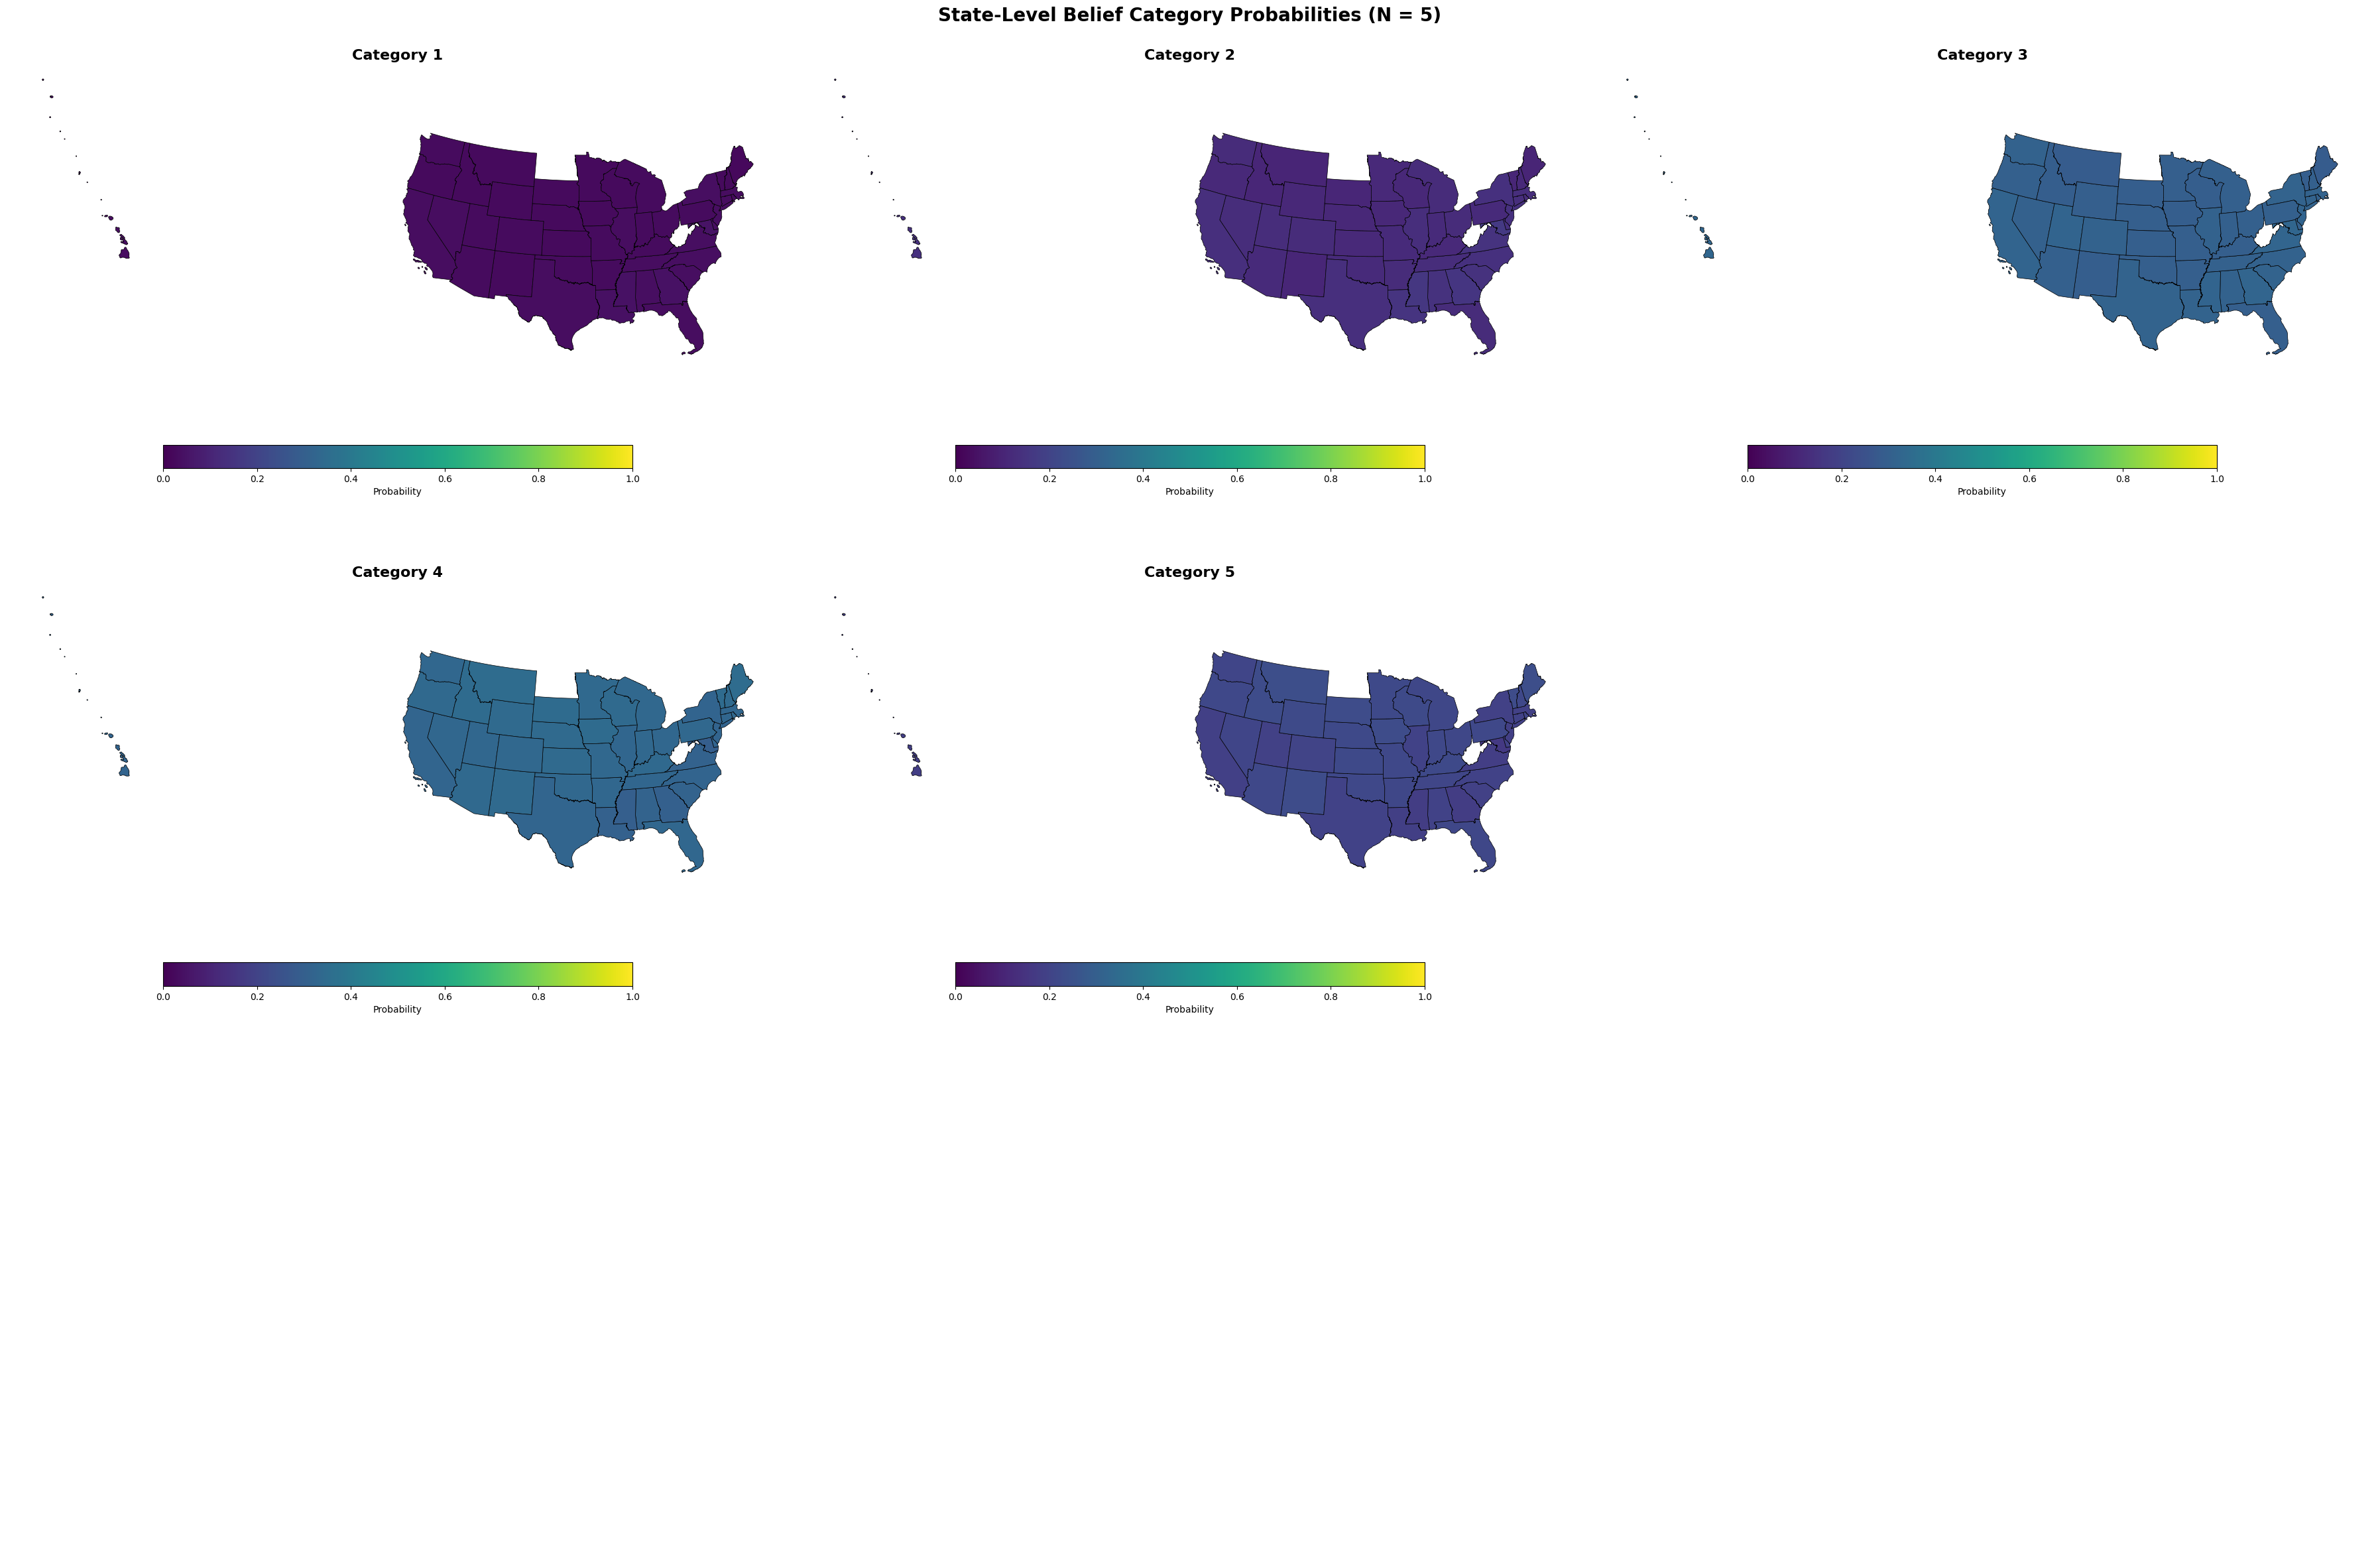

/tmp/ipykernel_1650/3719329641.py:158: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("RdYlGn", n)


✓ Dominant category map saved to /mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_n_white_share/dominant_category_map.png


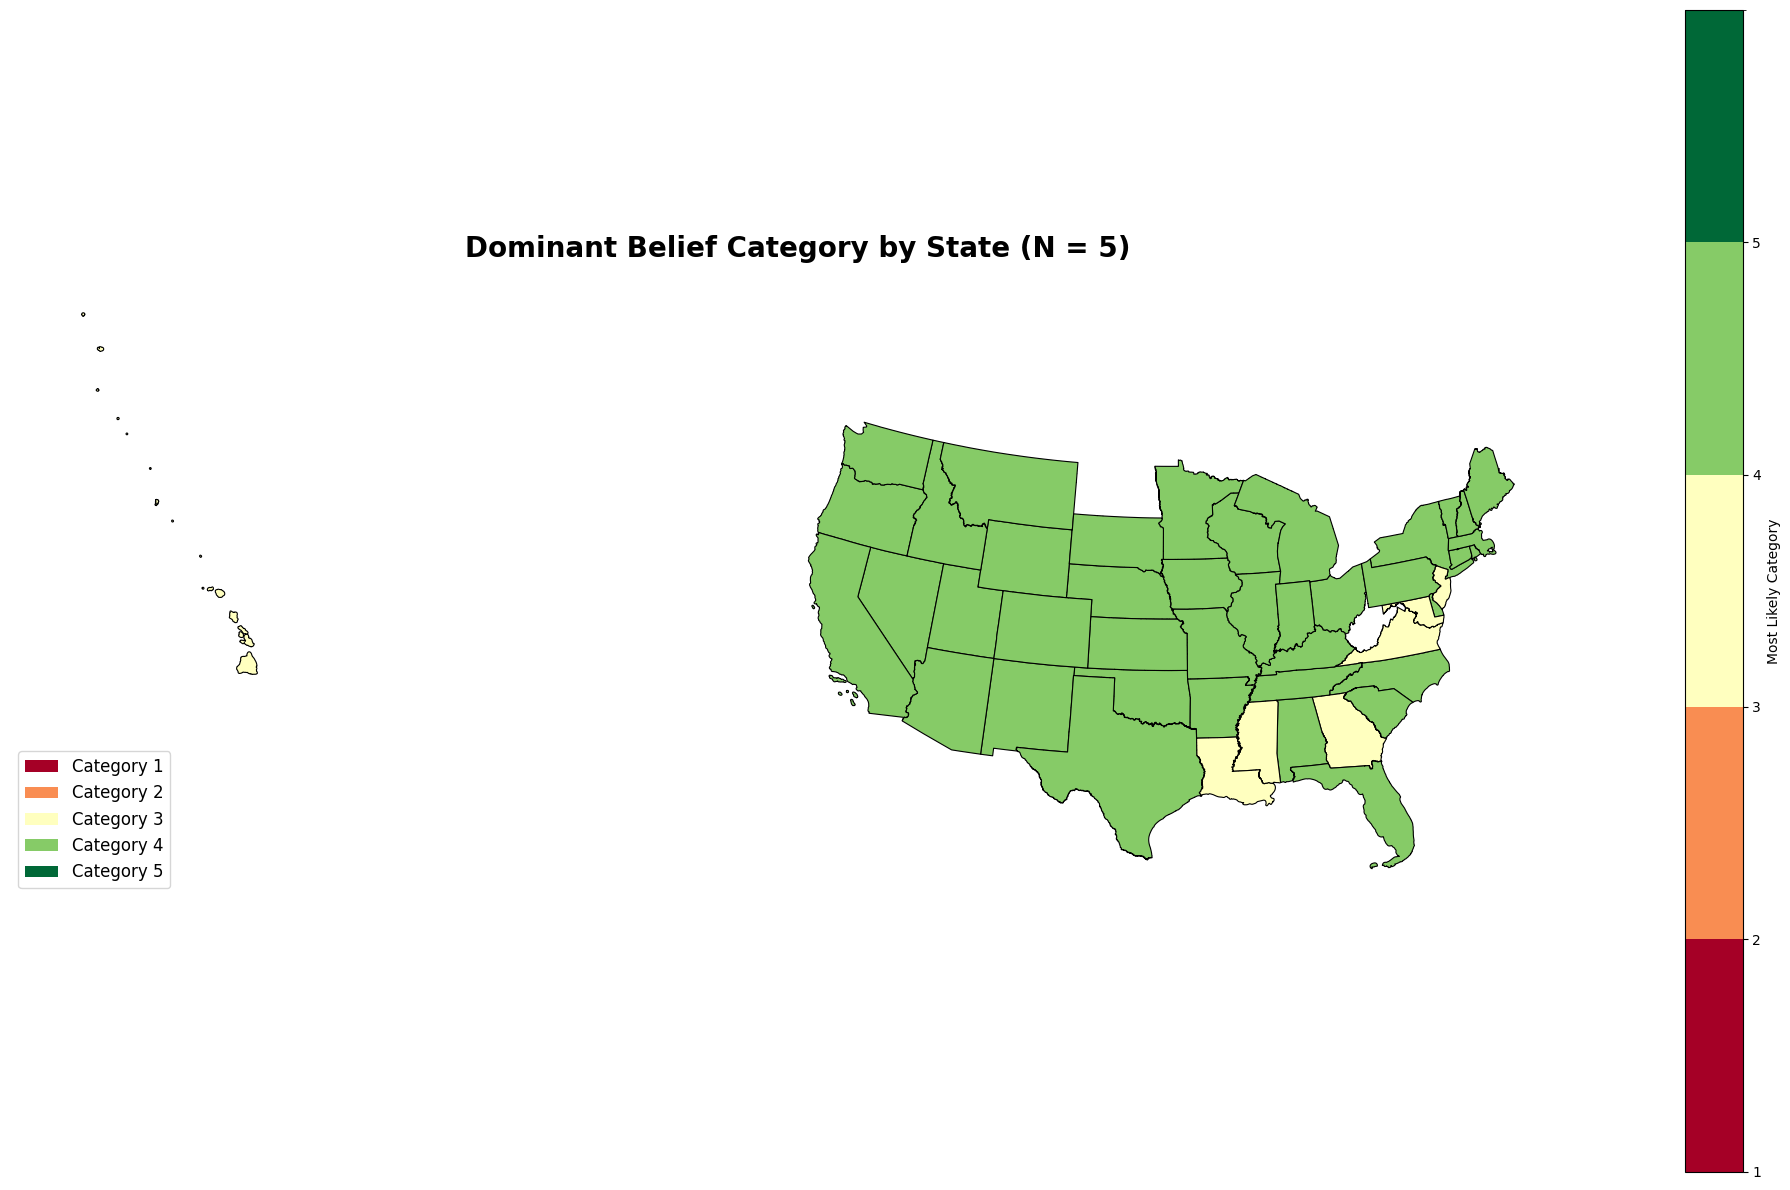


Dominant category by state:
  Category 1: 0 states
    []
  Category 2: 0 states
    []
  Category 3: 8 states
    ['District of Columbia', 'Georgia', 'Hawaii', 'Louisiana', 'Maryland', 'Mississippi', 'New Jersey', 'Virginia']
  Category 4: 40 states
  Category 5: 0 states
    []


In [25]:
def aggregate_probabilities_with_uncertainty(strat_frame, state_col='state_simple'):
    
    # Find N_star columns and probability columns
    n_star_cols = [col for col in strat_frame.columns 
                   if col.startswith('N_star.') and col != 'N_star.median']
    prob_cols = [col for col in strat_frame.columns if col.startswith('prob_cat_')]
    
    print(f"  Using {len(n_star_cols)} N_star samples")
    print(f"  Probability columns: {prob_cols}")
    
    state_results = []
    
    for state in strat_frame[state_col].unique():
        state_data = strat_frame[strat_frame[state_col] == state].copy()
        
        # For each N_star sample, compute weighted probabilities
        prob_samples = {prob_col: [] for prob_col in prob_cols}
        
        for n_col in n_star_cols:
            # Normalize weights for this sample
            weights = state_data[n_col] / state_data[n_col].sum()
            
            # Weighted average of each probability
            for prob_col in prob_cols:
                weighted_prob = np.average(state_data[prob_col], weights=weights)
                prob_samples[prob_col].append(weighted_prob)
        
        # Summarize: mean across all N_star samples
        result = {state_col: state}
        for prob_col in prob_cols:
            result[prob_col] = np.mean(prob_samples[prob_col])
            result[f'{prob_col}_lower'] = np.percentile(prob_samples[prob_col], 2.5)
            result[f'{prob_col}_upper'] = np.percentile(prob_samples[prob_col], 97.5)
        
        state_results.append(result)
    
    state_probs = pd.DataFrame(state_results)
    
    print(f" Aggregated {len(state_probs)} states with uncertainty")
    
    # Verify probabilities sum to ~1
    prob_sum = state_probs[prob_cols].sum(axis=1)
    print(f"  Mean probability sum: {prob_sum.mean():.4f} (should be ~1.0)")
    
    return state_probs


state_probs = aggregate_probabilities_with_uncertainty(strat_frame, 'state_simple')

print("\nColumns in state_probs:")
print(state_probs.columns.tolist())

# Visualize
plot_categorical_probabilities(state_probs, shp_path, 'state_simple')
plot_dominant_category(state_probs, shp_path, 'state_simple')

In [ ]:
# List of states with dominant "neither good nor bad"
neutral_states = ['District of Columbia', 'Georgia', 'Hawaii', 'Louisiana', 
                  'Maryland', 'Mississippi', 'New Jersey', 'Virginia']

# Identify probability columns
prob_cols = [c for c in state_probs.columns if c.startswith('prob_cat_')]
print(prob_cols)
# Select relevant states and columns
neutral_probs = state_probs[state_probs['state_simple'].isin(neutral_states)][['state_simple'] + prob_cols]

for idx, row in neutral_probs.iterrows():
    print(f"\nState: {row['state_simple']}")
    for col in prob_cols:
        print(f"  {col}: {row[col]:.4f}")


['prob_cat_1', 'prob_cat_1_lower', 'prob_cat_1_upper', 'prob_cat_2', 'prob_cat_2_lower', 'prob_cat_2_upper', 'prob_cat_3', 'prob_cat_3_lower', 'prob_cat_3_upper', 'prob_cat_4', 'prob_cat_4_lower', 'prob_cat_4_upper', 'prob_cat_5', 'prob_cat_5_lower', 'prob_cat_5_upper']

State: District of Columbia
  prob_cat_1: 0.0594
  prob_cat_1_lower: 0.0594
  prob_cat_1_upper: 0.0594
  prob_cat_2: 0.2024
  prob_cat_2_lower: 0.2023
  prob_cat_2_upper: 0.2024
  prob_cat_3: 0.3572
  prob_cat_3_lower: 0.3571
  prob_cat_3_upper: 0.3573
  prob_cat_4: 0.2616
  prob_cat_4_lower: 0.2615
  prob_cat_4_upper: 0.2616
  prob_cat_5: 0.1195
  prob_cat_5_lower: 0.1195
  prob_cat_5_upper: 0.1195

State: Georgia
  prob_cat_1: 0.0432
  prob_cat_1_lower: 0.0432
  prob_cat_1_upper: 0.0432
  prob_cat_2: 0.1560
  prob_cat_2_lower: 0.1560
  prob_cat_2_upper: 0.1560
  prob_cat_3: 0.3204
  prob_cat_3_lower: 0.3203
  prob_cat_3_upper: 0.3204
  prob_cat_4: 0.3028
  prob_cat_4_lower: 0.3028
  prob_cat_4_upper: 0.3028
  prob_ca